<a href="https://colab.research.google.com/github/dionis-razin/Quant_finance_projects/blob/main/moving_average_crossover_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Бэктест пересечения скользящих средних

Цель проекта — на примере простой трендовой стратегии (пересечение 50-дневной и 200-дневной скользящих средних на `SPY`) проверить, как на реальную доходность влияют задержка исполнения на 1 день, транзакционные издержки и сравнение с пассивной стратегией **Buy & Hold**.

### Шаг 1. Загрузка данных и расчёт скользящих средних

Загружаем дневные цены закрытия ETF на индекс S&P 500 (`SPY`) с поправкой на дивиденды и сплиты (`auto_adjust=True`) и рассчитываем две простые скользящие средние:
- **`SMA_50`** — средняя цена за последние 50 торговых дней (примерно 2.5 месяца), отражает краткосрочный тренд.
- **`SMA_200`** — средняя цена за последние 200 торговых дней (почти год), отражает долгосрочный тренд.

[*********************100%***********************]  1 of 1 completed


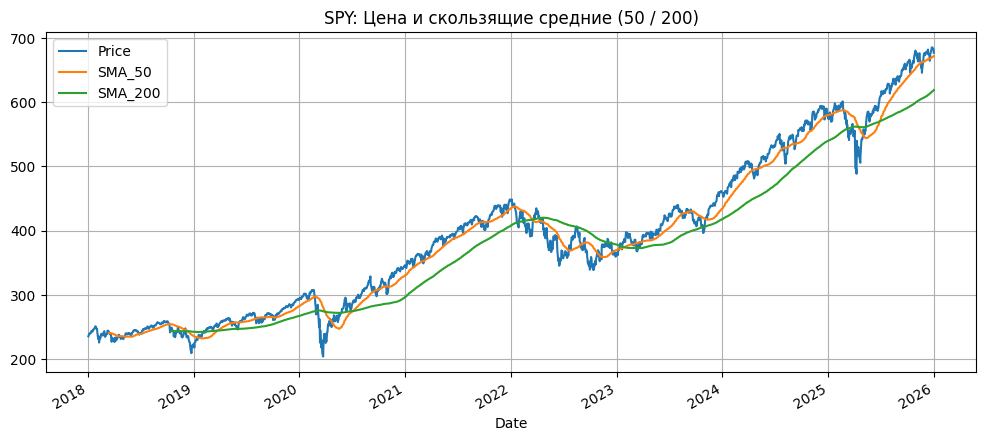

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

data = yf.download('SPY', start='2018-01-01', end='2026-01-01', auto_adjust=True)
df = data[['Close']].copy()
df.columns = ['Price']

df['SMA_50'] = df['Price'].rolling(window=50).mean()
df['SMA_200'] = df['Price'].rolling(window=200).mean()

df.plot(figsize=(12, 5), title='SPY: Цена и скользящие средние (50 / 200)')
plt.grid(True)
plt.show()

### Шаг 2. Генерация сигналов и задержка исполнения на 1 день

Базовое правило стратегии простое: мы покупаем и держим `SPY`, пока краткосрочный тренд (`SMA_50`) выше долгосрочного (`SMA_200`), и выходим в деньги, как только эта ситуация меняется.

Главная ловушка простых бэктестов — **подглядывание в будущее (look-ahead bias)**. Пересечение скользящих средних фиксируется только после закрытия торгового дня, поэтому реально открыть или закрыть позицию можно не раньше следующего дня.

**Как работает расчёт:**
- **`Signal`:** торговый сигнал на конец дня (`1`, если `SMA_50 > SMA_200`, иначе `0`).
- **`Position`:** реальная позиция в портфеле, сдвинутая на 1 день вперёд с помощью `.shift(1)`. Именно она защищает бэктест от использования будущих данных.
- **`Market_Ret`:** дневное процентное изменение цены `SPY` (`pct_change()`).
- **`Naive_Ret` vs `Strategy_Ret`:** сравниваем «наивную» доходность (если бы мы торговали в день появления сигнала) с честной доходностью (с задержкой на 1 день). Итоговый результат за весь период считается через сложный процент: `(1 + ret).cumprod()`.

In [2]:
import numpy as np

df['Signal'] = np.where(df['SMA_50'] > df['SMA_200'], 1, 0)
df['Position'] = df['Signal'].shift(1).fillna(0)

df['Market_Ret'] = df['Price'].pct_change()
df['Naive_Ret'] = df['Signal'] * df['Market_Ret']
df['Strategy_Ret'] = df['Position'] * df['Market_Ret']

print(f"Без задержки: {((1 + df['Naive_Ret']).cumprod().iloc[-1] - 1):.2%}")
print(f"С задержкой (1 день): {((1 + df['Strategy_Ret']).cumprod().iloc[-1] - 1):.2%}")

Без задержки: 99.38%
С задержкой (1 день): 85.75%


### Шаг 3. Учёт транзакционных издержек (комиссии и проскальзывание)

На исторических данных стратегия всегда выглядит лучше, чем в реальности, если не учитывать расходы на исполнение сделок. Чтобы приблизить бэктест к практике, закладываем **0.1%** (`0.001`) на каждую покупку и продажу — это суммарный учёт брокерской комиссии и проскальзывания цены.

**Как работает расчёт:**
- **`Trades`:** находим дни совершения сделок через `df['Position'].diff().abs()`. Разница между сегодняшней и вчерашней позицией даёт `1` при покупке (`0 → 1`), `-1` при продаже (`1 → 0`) и `0` при удержании. Функция `.abs()` убирает минус, превращая любую сделку в `1`.
- **`Strategy_Net_Ret`:** вычитаем `0.1%` из дневной доходности стратегии (`Strategy_Ret`) именно в те дни, когда `Trades == 1`.
- **Сравнение результатов:** считаем общее количество сделок за весь период и сравниваем итоговую накопленную доходность до (`gross_ret`) и после (`net_ret`) списания издержек.

In [3]:
cost = 0.001
df['Trades'] = df['Position'].diff().abs().fillna(0)
df['Strategy_Net_Ret'] = df['Strategy_Ret'] - df['Trades'] * cost

gross_ret = (1 + df['Strategy_Ret']).cumprod().iloc[-1] - 1
net_ret = (1 + df['Strategy_Net_Ret']).cumprod().iloc[-1] - 1

print(f"Всего сделок: {int(df['Trades'].sum())}")
print(f"Доходность до комиссий: {gross_ret:.2%}")
print(f"Доходность после комиссий: {net_ret:.2%}")

Всего сделок: 9
Доходность до комиссий: 85.75%
Доходность после комиссий: 84.09%


### Шаг 4. Сравнение со стратегией Buy & Hold

Даже если активная стратегия приносит прибыль, её всегда сравнивают с базовым ориентиром — пассивной стратегией **Buy & Hold** («купил `SPY` в первый день и ничего не делал»). Если алгоритм не обгоняет рынок по доходности, единственный смысл в его существовании — заметно более низкий риск и меньшие просадки.

**Как работает расчёт:**
Функция `get_metrics` рассчитывает четыре ключевых показателя для нашей стратегии (уже после списания комиссий) и для обычного удержания `SPY`:
- **Накопленная доходность (`total_ret`):** общий процентный рост капитала за весь период.
- **Годовая доходность (`CAGR`):** среднегодовой темп роста с учётом сложного процента (приведённый к 252 торговым дням в году).
- **Максимальная просадка (`max_dd`):** самое глубокое падение капитала от исторического пика до локального дна. Показывает, какой максимальный убыток пришлось бы пересиживать.
- **Коэффициент Шарпа (`sharpe`):** отношение доходности к волатильности (риску). Чем выше значение, тем стабильнее и «ровнее» растёт капитал.

В конце строим график накопленной доходности обеих стратегий на одних осях, чтобы визуально оценить поведение алгоритма в периоды роста и рыночных падений.

                          SMA 50/200 (Net) Buy & Hold (SPY)
Накопленная доходность              84.09%          187.48%
Годовая доходность (CAGR)            7.95%           14.16%
Макс. просадка                     -33.72%          -33.72%
Коэффициент Шарпа                     0.57             0.78


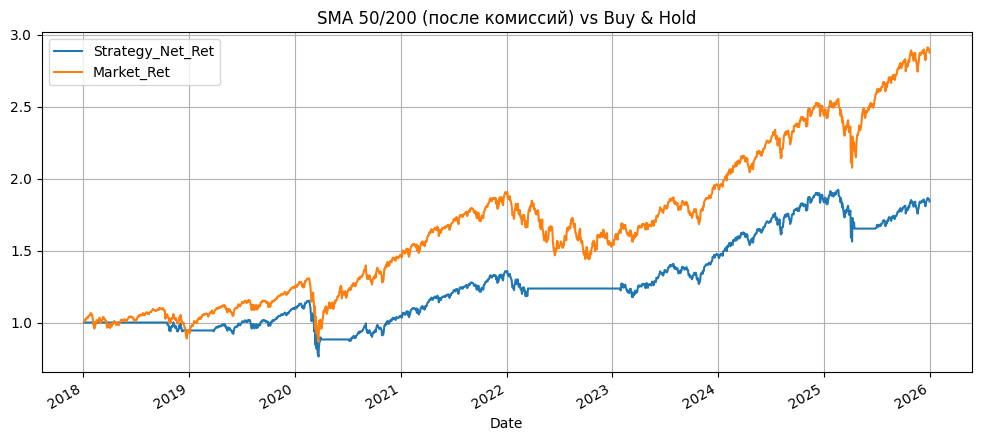

In [4]:
import pandas as pd

def get_metrics(ret):
    ret = ret.dropna()
    cum_ret = (1 + ret).cumprod()
    total_ret = cum_ret.iloc[-1] - 1
    ann_ret = (1 + total_ret) ** (252 / len(ret)) - 1
    sharpe = (ret.mean() / ret.std()) * np.sqrt(252)
    max_dd = (cum_ret / cum_ret.cummax() - 1).min()
    return pd.Series({
        'Накопленная доходность': f'{total_ret:.2%}',
        'Годовая доходность (CAGR)': f'{ann_ret:.2%}',
        'Макс. просадка': f'{max_dd:.2%}',
        'Коэффициент Шарпа': f'{sharpe:.2f}'
    })

comparison = pd.DataFrame({
    'SMA 50/200 (Net)': get_metrics(df['Strategy_Net_Ret']),
    'Buy & Hold (SPY)': get_metrics(df['Market_Ret'])
})
print(comparison)

(1 + df[['Strategy_Net_Ret', 'Market_Ret']]).cumprod().plot(
    figsize=(12, 5), title='SMA 50/200 (после комиссий) vs Buy & Hold'
)
plt.grid(True)
plt.show()

### Шаг 5. Итоги и выводы по проекту (Moving Average Crossover: SPY)

В ходе проекта мы протестировали классическую трендовую стратегию пересечения скользящих средних (`SMA 50 / 200`) на ETF индекса S&P 500 (`SPY`) за 2018–2026 годы с учётом задержки исполнения на 1 день и транзакционных издержек (`0.1%` за сделку).

**Ключевые результаты (после комиссий vs Buy & Hold):**
- **Накопленная доходность:** `84.09%` против `187.48%` у Buy & Hold.
- **Годовая доходность (CAGR):** `7.95%` против `14.16%`.
- **Максимальная просадка:** `-33.72%` у обеих стратегий.
- **Коэффициент Шарпа:** `0.57` против `0.78`.

**Главные практические выводы:**
1. **Стратегия проиграла пассивному удержанию по всем метрикам.** Она принесла более чем вдвое меньше прибыли, показала худшее соотношение доходности к риску (Sharpe) и не смогла снизить максимальную просадку.
2. **Поведение в разных рыночных фазах:**
   - **Медленные затяжные тренды (как в 2022 году):** стратегия работает хорошо — успевает вовремя выйти в деньги и переждать плавное снижение рынка.
   - **Резкие обвалы и V-образные отскоки (весна 2020 и 2025 годов):** главный враг скользящих средних. Из-за запаздывания алгоритм падает вместе с рынком, продаёт уже близко ко дну и пропускает значительную часть быстрого восстановления.
   - **Боковой рынок:** частые ложные пересечения приводят к серии мелких убытков.
3. **Влияние комиссий и задержки:** для медленных средних `50 / 200` сделок за 8 лет немного, поэтому комиссии `0.1%` и сдвиг на 1 день влияют на итог умеренно (в отличие от более быстрых стратегий, где издержки способны полностью обнулить прибыль). Тем не менее задержка исполнения обязательна для честного бэктеста, чтобы исключить подглядывание в будущее

**Итог:** на растущем в долгосрочной перспективе рынке акций (`SPY`) простое пересечение `SMA 50 / 200` не оправдывает себя и уступает базовой стратегии **Buy & Hold**